# Lateral Inhibition Mechanism
- Python program for the numerical solution of the following system of non-linear, coupled, 1st order, ordinary differential equations:

$ \frac{dN_{1}}{d\tau} = f(D_{2}) - N_{1} $

$ \frac{dD_{1}}{d\tau} = \nu[f(gN_{1}) - D_{1}] $

$ \frac{dN_{2}}{d\tau} = f(D_{1}) - N_{2} $

$ \frac{dD_{2}}{d\tau} = \nu[f(gN_{2}) - D_{2}] $


- These system of equations model cell signalling and the mechanism of lateral inhibition between two adjacent cells in contact with each other.
- $(N_{1},D_{1})$ and $(N_{2},D_{2})$ denote Notch and Delta (molecular species with Notch as receptor and Delta as ligand) activities within neighbouring cells 1 and 2 respectively. The functions $f$ and $g$ are non-linear functions of Notch and Delta activities respectively. The dimensionless constant $\nu$ is the ratio of the decay rates of Delta and Notch, while $\tau$ here denotes the dimensionless development time.
- Solution method: 4th order Runge-Kutta method


 The final levels of Notch activity determine the fate of each cell, while Delta is used in cell signalling between the cells. The lateral inhibition mechanism describes how high levels of Notch activity in one cell leads to its fate, but this cell also signals to the neighbouring cell to lower its Notch activity, leading to a different cell fate for the neighbouring cell [1,2].

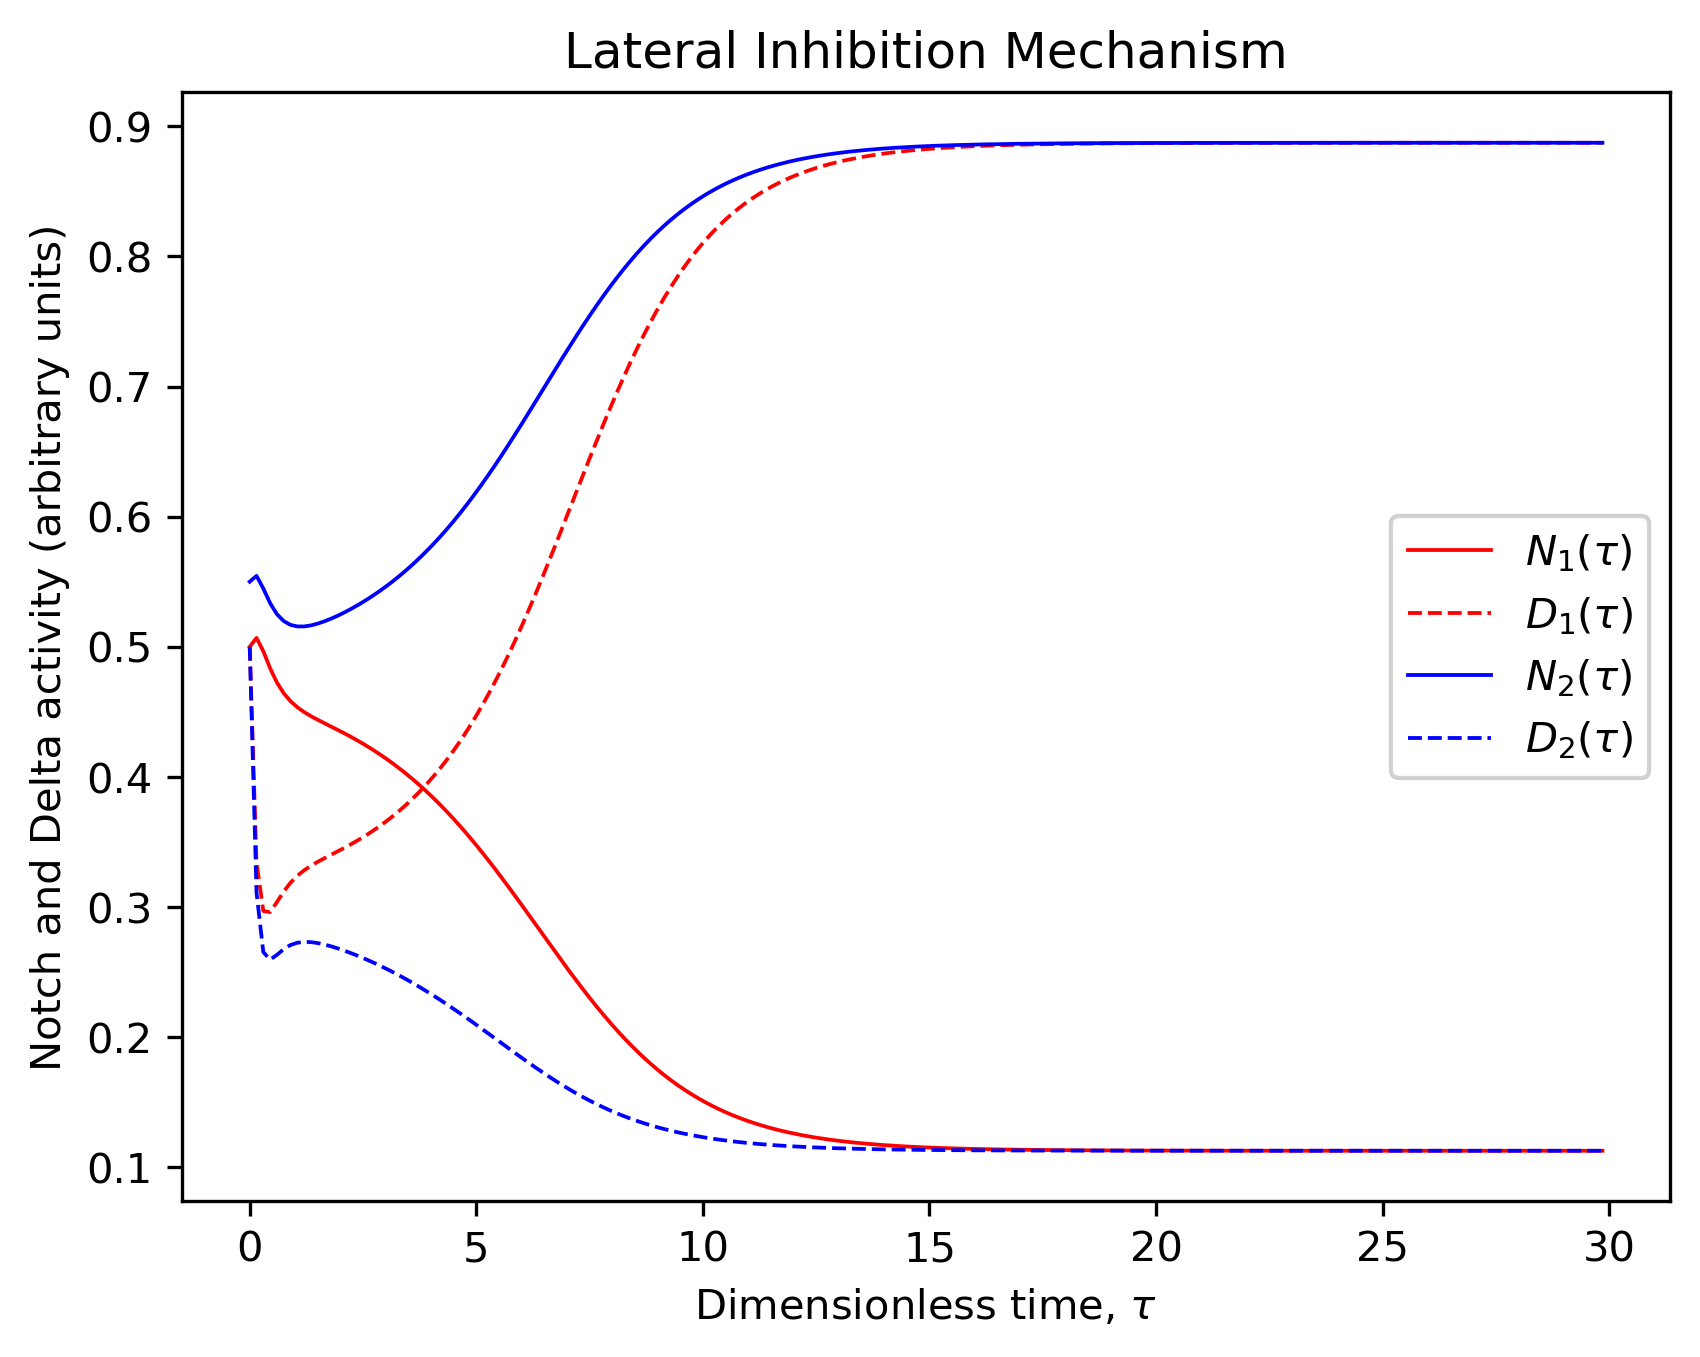

In [2]:
"""
@author: Apoorva Upadhyay
"""

from numpy import *
from matplotlib.pyplot import *
import numpy as np
import decimal
from decimal import Decimal

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi']=300 # highres display

from mpl_toolkits.mplot3d import Axes3D # import 3d plotting tool

import os

import re

import pandas as pd

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
#plt.rcParams['text.usetex'] = True

import math
import statistics

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

from matplotlib.animation import PillowWriter
from matplotlib.animation import FFMpegFileWriter
from matplotlib.animation import FFMpegWriter

import matplotlib.gridspec as gridspec

#################################################


#############################################################################
# example 2: systems of ODEs
# dx/dt = xy - x
# dy/dt = y - xy + sin^2(wt)
# calculate x(t) and y(t) from t=0 to t=10
# for the case w=1
# ICs: x(t=0)=1, y(t=0)=1
# Using vectorised 4th order runge kutta

# general form (not fully but will do for now) for system of 1st order ODEs:
# dx/dt = f_x(x,y,t)
# dy/dt = f_y(x,y,t)

# for an arbitrary number of dependent variables x,y,... the system of 1st order ODEs
# can be written in vector notation as:
# dr/dt = f(r,t)
# where r = (x,y,...) = vector, with components as dependent variables
# f(r,t) = (f_x(r,t), f_y(r,t), ...) = vector, with components as 
# functions f_x(r,t) = f_x(x,y,...,t) etc

# note: function f(r,t) now takes in r as an array and t as a variable
# previously for function f(x,t); x was a variable input, not an array input.
# f(r,t) returns a vector with components as functions f_x and f_y
def f(r,tau):
    N_1 = r[0] # first component of vector r = dependent variable x
    D_1 = r[1] # second component of vector r = dependent variable y
    N_2 = r[2]
    D_2 = r[3]
    
    nu = 10.0
    
    f_n1 = ((D_2**2)/(0.1 + D_2**2)) - N_1 # f_x =  f_x(r,t) = f_x(x,y,t) = first component of vector f(r,t)
    f_d1 = nu * ((1.0/(1.0 + 10.0*N_1**2 )) - D_1)
    
    f_n2 = ((D_1**2)/(0.1 + D_1**2)) - N_2
    f_d2 = nu * ((1.0/(1.0 + 10.0*N_2**2 )) - D_2)
    
    return np.array([f_n1, f_d1, f_n2, f_d2], dtype=float)


# dicretise time t "axis", tau = dimensionless time
tau_min = 0.0
tau_max = 30.0
#delta_t = 0.1
N = 200 # number of time steps, from which we can calculate delta_t
delta_tau = (tau_max - tau_min)/N # 10/10 = 1.0 seconds (delta_t = h in book)


tau_time_points = np.arange(tau_min,tau_max,delta_tau) # array
N_1_points = []
D_1_points = []
N_2_points = []
D_2_points = []

# ICs:
r = np.array([0.5, 0.5, 0.55, 0.5], dtype=float) # vector r, with its intital values of its components at t=0
# think of the entire problem like this: we have to solve
# for vector r = (x,y,...) = r = (x(t),y(t),...)
# so ICs are: r = (x(t=0)=1,y(t=0)=1,...) = (1.0, 1.0, ...)

# WE ARE NOT SOLVING FOR f_x and f_y ; THEY ARE JUST THE RHS OF THE system of ODEs

# vectorised 4RK
for k in tau_time_points:
    
    N_1_points.append(r[0]) # append new_x (r[0]) when loop starts again
    D_1_points.append(r[1]) # append new_y (r[1]) when loop starts again
    # remember: r = (x,y,...) = r = (x(t),y(t),...)
    
    N_2_points.append(r[2])
    D_2_points.append(r[3])
    
    
    k1 = delta_tau * f(r,k)
    k2 = delta_tau * f(r+0.5*k1, k+0.5*delta_tau)
    k3 = delta_tau * f(r+0.5*k2, k+0.5*delta_tau)
    k4 = delta_tau * f(r+k3, k+delta_tau)
    r = r + (k1 + 2*k2 + 2*k3 + k4)/6.0 # new_r = old_r + calculations(using old_r)
    
    # new value of r (new_r) appended at beginning of next loop
    
fig = plt.figure()

plt.plot(tau_time_points, N_1_points, color='red', linewidth=0.9, label=r'$N_{1}(\tau)$')
plt.plot(tau_time_points, D_1_points, '--', color='red', linewidth=0.9, label=r'$D_{1}(\tau)$')

plt.plot(tau_time_points, N_2_points, color='blue', linewidth=0.9, label=r'$N_{2}(\tau)$')
plt.plot(tau_time_points, D_2_points, '--', color='blue', linewidth=0.9, label=r'$D_{2}(\tau)$')

legend1 = plt.legend(prop={'size': 10},loc= "center right")#,loc=(0.0,.25)) loc = "center right", loc= "upper right"
plt.gca().add_artist(legend1)

plt.ylabel(r'Notch and Delta activity (arbitrary units)', fontsize=10)
plt.xlabel(r'Dimensionless time, $\tau$',fontsize=10)

#plt.xlim([-1.0,30.0])

#plt.savefig('NotchDelta.pdf',bbox_inches = 'tight', dpi=200)
plt.title('Lateral Inhibition Mechanism')

plt.show()

Figure above shows numerical simulation of the time evolution of Notch and Delta activities, as functions of development time $\tau$, within two cells (labelled 1 and 2) in contact with each other.

The system of equations are numerically and simultaneously solved  for levels of Notch and Delta activity in cells 1 and 2, using the 4th order Runge-Kutta method. The initial conditions used are (arbitrary units): $N_1(\tau = 0) = 0.50, N_2(\tau = 0) = 0.55, D_1(\tau = 0) = 0.50, D_2(\tau = 0) = 0.50$ The dimensionless constant $\nu$ is chosen to be equal to 10.0 which means that the decay rate of Delta is much larger than that of Notch. The simulation is run for a maximum value of $\tau$ = 30.

The results of the simulation in the figure above show that initial differences in Notch activities of cells 1 and 2 are amplified over time, leading to very high levels Notch activity in cell number 2 and very low Notch activity in cell number 1, leading to different cell fates as predicted by the lateral inhibition mechanism. Although the predictions of this numerical model seem physical and logical, I am currently searching for research articles and studies where experimental data is available to verify the model predictions.

References:

[1] Collier, J. R., Monk, N. A., Maini, P. K., & Lewis, J. H. (1996). Pattern formation by lateral inhibition with feedback: a mathematical model of delta-notch intercellular signalling. Journal of theoretical Biology, 183(4), 429-446.

[2] Phillips, R., Kondev, J., Theriot, J., Garcia, H.G. (2013). Physical Biology of the Cell, 2nd ed., CRC Press, Taylor & Francis Group
